# London Overground Network
## Complete Overground Map with Geographic Coverage

This notebook visualizes the London Overground network, which was rebranded in 2024 into six named lines:
- **Liberty** (Romford to Upminster)
- **Lioness** (Euston to Watford Junction)
- **Mildmay** (Stratford to Richmond/Clapham Junction)
- **Suffragette** (Gospel Oak to Barking Riverside)
- **Weaver** (Liverpool Street to Enfield Town/Cheshunt/Chingford)
- **Windrush** (Highbury & Islington to Clapham Junction/Crystal Palace/West Croydon)

In [1]:
import pyarrow.feather as feather
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Polygon
from scipy.spatial import ConvexHull
from scipy.ndimage import gaussian_filter
from pathlib import Path

# Set up paths
DATA_DIR = Path('../data/processed_data')
OUTPUT_DIR = Path('../output')
OUTPUT_DIR.mkdir(exist_ok=True)

# London Overground line colors (official TfL 2024 rebrand)
OVERGROUND_COLORS = {
    'LIB': '#6B717A',  # Liberty - Grey
    'LIO': '#FFA600',  # Lioness - Orange
    'MIL': '#00A0E2',  # Mildmay - Blue
    'SUF': '#00853E',  # Suffragette - Green
    'WEA': '#9B0058',  # Weaver - Maroon
    'WIN': '#E21836',  # Windrush - Red
}

OVERGROUND_NAMES = {
    'LIB': 'Liberty',
    'LIO': 'Lioness',
    'MIL': 'Mildmay',
    'SUF': 'Suffragette',
    'WEA': 'Weaver',
    'WIN': 'Windrush',
}

OVERGROUND_ROUTES = {
    'LIB': 'Romford ↔ Upminster',
    'LIO': 'Euston ↔ Watford Junction',
    'MIL': 'Stratford ↔ Richmond / Clapham Junction',
    'SUF': 'Gospel Oak ↔ Barking Riverside',
    'WEA': 'Liverpool Street ↔ Enfield Town / Cheshunt / Chingford',
    'WIN': 'Highbury & Islington ↔ Clapham Junction / Crystal Palace / West Croydon',
}

## Load Data

In [2]:
# Load stop points
stops = feather.read_feather(DATA_DIR / 'ALL-StopPoints.feather')
print(f"Loaded {len(stops)} total stations")

# Convert coordinates
stops['Easting'] = pd.to_numeric(stops['Place_Location_Easting'])
stops['Northing'] = pd.to_numeric(stops['Place_Location_Northing'])

# Convert to lat/lon
try:
    from pyproj import Transformer
    transformer = Transformer.from_crs('EPSG:27700', 'EPSG:4326', always_xy=True)
    coords = transformer.transform(stops['Easting'].values, stops['Northing'].values)
    stops['Longitude'] = coords[0]
    stops['Latitude'] = coords[1]
except ImportError:
    stops['Latitude'] = 49.0 + (stops['Northing'] / 111000)
    stops['Longitude'] = -7.5 + (stops['Easting'] / (111000 * np.cos(np.radians(stops['Latitude']))))

# Create coordinate lookup
stop_coords = stops.set_index('AtcoCode')[['Easting', 'Northing', 'Latitude', 'Longitude', 'Descriptor_CommonName']].to_dict('index')

Loaded 802 total stations


In [3]:
def load_route_links(line_code):
    """Load route links for a specific line."""
    path = DATA_DIR / f'{line_code}-RouteLinks.feather'
    if path.exists():
        return feather.read_feather(path)
    return None

def get_unique_edges(route_links):
    """Extract unique station-to-station edges."""
    return route_links[['From_StopPointRef', 'To_StopPointRef']].drop_duplicates()

# Load all Overground lines
overground_edges = {}
for line_code in OVERGROUND_COLORS.keys():
    links = load_route_links(line_code)
    if links is not None:
        edges = get_unique_edges(links)
        overground_edges[line_code] = edges
        print(f"{OVERGROUND_NAMES[line_code]:15s} ({line_code}): {len(edges):3d} edges - {OVERGROUND_ROUTES[line_code]}")
    else:
        print(f"{OVERGROUND_NAMES[line_code]:15s} ({line_code}): No data")

print(f"\nTotal Overground lines loaded: {len(overground_edges)}")

Liberty         (LIB):   4 edges - Romford ↔ Upminster
Lioness         (LIO):  36 edges - Euston ↔ Watford Junction
Mildmay         (MIL):  54 edges - Stratford ↔ Richmond / Clapham Junction
Suffragette     (SUF):  24 edges - Gospel Oak ↔ Barking Riverside
Weaver          (WEA):  48 edges - Liverpool Street ↔ Enfield Town / Cheshunt / Chingford
Windrush        (WIN):  58 edges - Highbury & Islington ↔ Clapham Junction / Crystal Palace / West Croydon

Total Overground lines loaded: 6


In [4]:
def plot_line(ax, edges, stop_coords, color, linewidth=2, alpha=0.8):
    """Plot a single line on the axes."""
    for _, edge in edges.iterrows():
        from_stop = edge['From_StopPointRef']
        to_stop = edge['To_StopPointRef']
        
        if from_stop in stop_coords and to_stop in stop_coords:
            x = [stop_coords[from_stop]['Easting'], stop_coords[to_stop]['Easting']]
            y = [stop_coords[from_stop]['Northing'], stop_coords[to_stop]['Northing']]
            ax.plot(x, y, color=color, linewidth=linewidth, alpha=alpha, solid_capstyle='round')

def get_network_stations(all_edges, stop_coords):
    """Get all stations with valid coordinates."""
    stations = set()
    for edges in all_edges.values():
        stations.update(edges['From_StopPointRef'].tolist())
        stations.update(edges['To_StopPointRef'].tolist())
    return [s for s in stations if s in stop_coords]

def get_terminus_stations(edges):
    """Find terminus stations (appear only once in edges)."""
    station_counts = {}
    for _, edge in edges.iterrows():
        station_counts[edge['From_StopPointRef']] = station_counts.get(edge['From_StopPointRef'], 0) + 1
        station_counts[edge['To_StopPointRef']] = station_counts.get(edge['To_StopPointRef'], 0) + 1
    return [s for s, count in station_counts.items() if count == 1]

## Individual Overground Lines

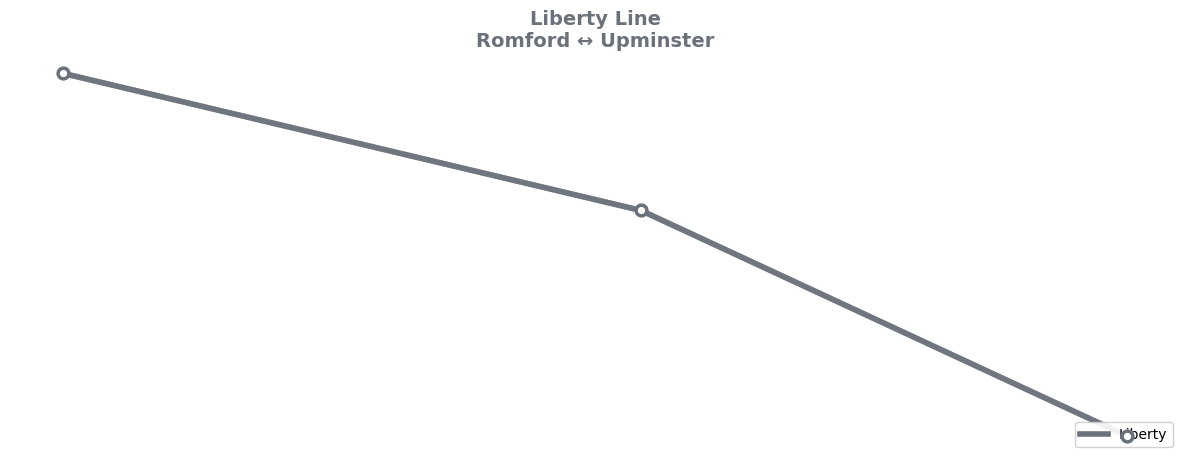

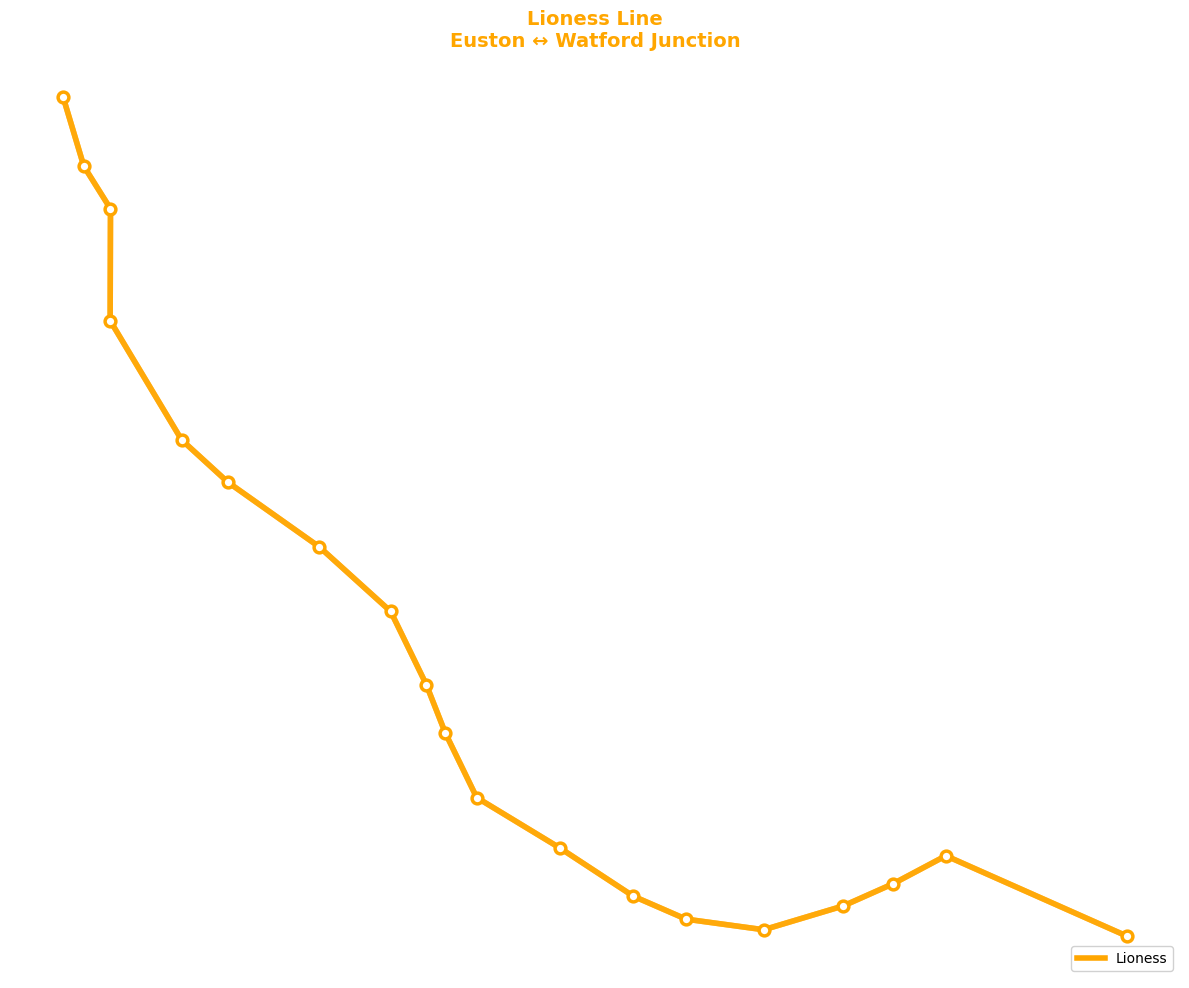

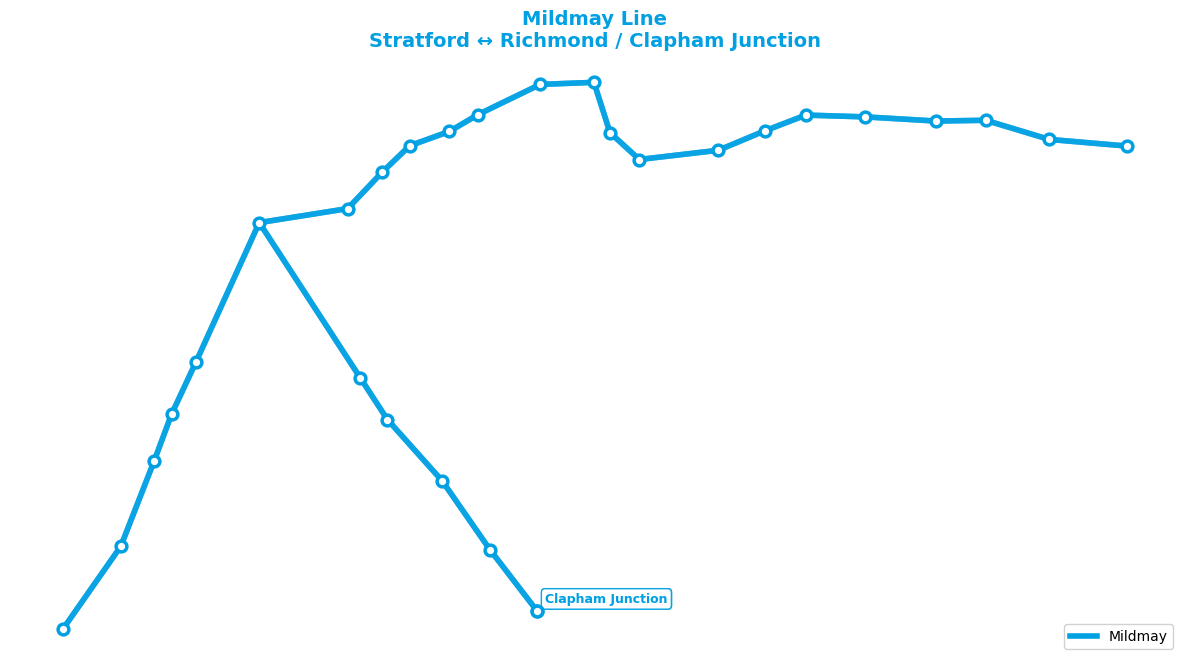

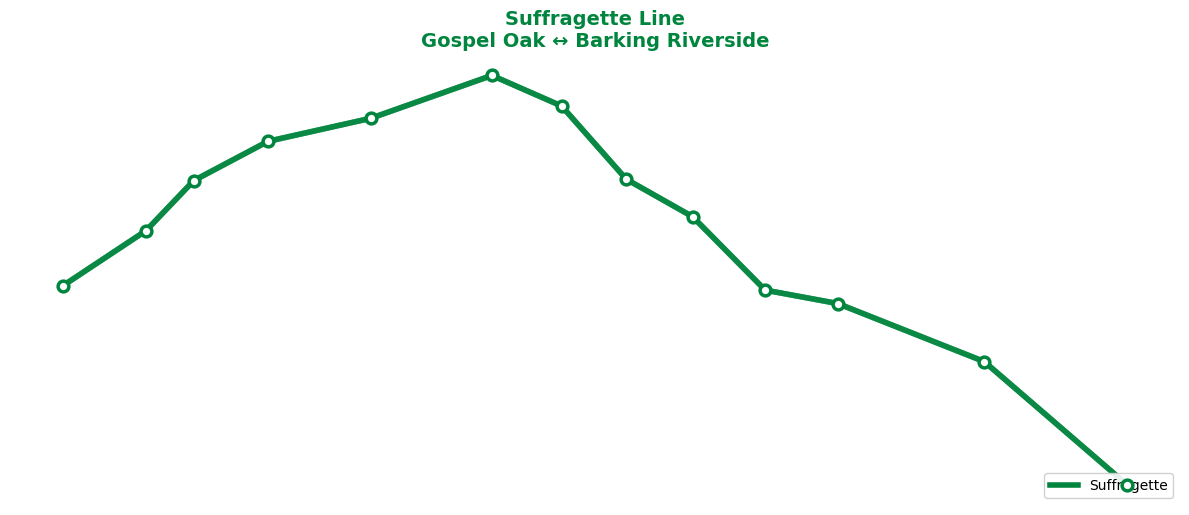

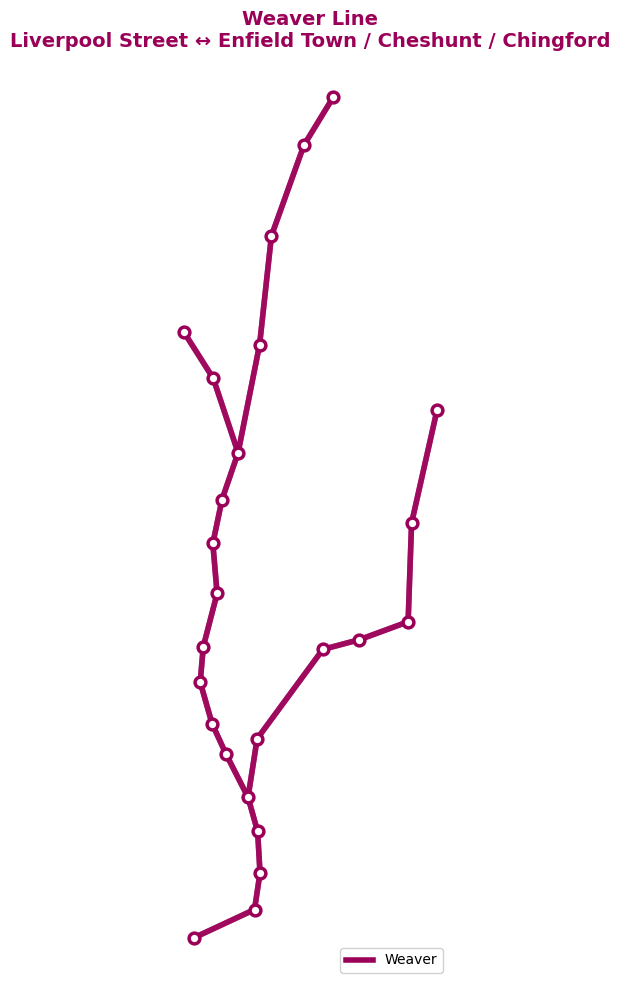

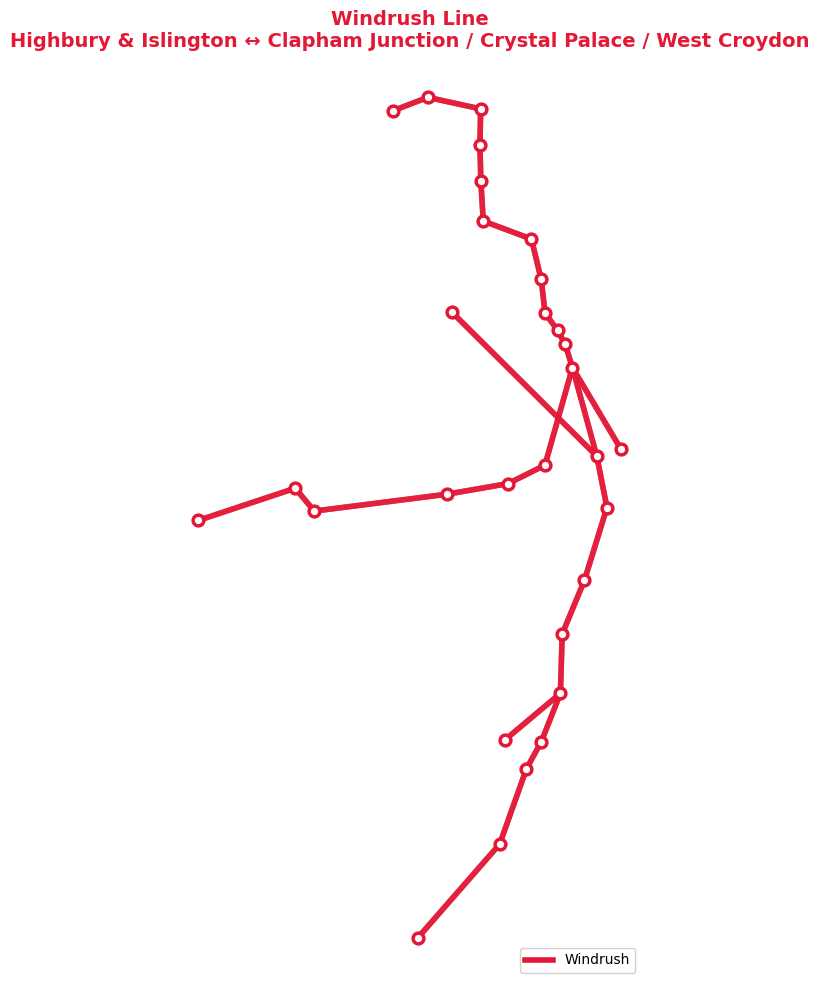

In [5]:
# Plot each Overground line individually
for line_code, edges in overground_edges.items():
    fig, ax = plt.subplots(figsize=(12, 10))
    
    color = OVERGROUND_COLORS[line_code]
    name = OVERGROUND_NAMES[line_code]
    route = OVERGROUND_ROUTES[line_code]
    
    # Get stations on this line
    line_stations = set(edges['From_StopPointRef'].tolist() + edges['To_StopPointRef'].tolist())
    
    # Draw edges
    plot_line(ax, edges, stop_coords, color, linewidth=4)
    
    # Draw stations
    for station in line_stations:
        if station in stop_coords:
            ax.scatter(stop_coords[station]['Easting'], stop_coords[station]['Northing'],
                      c='white', s=60, edgecolors=color, linewidth=2.5, zorder=10)
    
    # Label terminus stations
    terminus = get_terminus_stations(edges)
    for station in terminus:
        if station in stop_coords:
            station_name = stop_coords[station].get('Descriptor_CommonName', '')
            if station_name:
                ax.annotate(station_name, 
                           (stop_coords[station]['Easting'], stop_coords[station]['Northing']),
                           xytext=(6, 6), textcoords='offset points',
                           fontsize=9, color=color, fontweight='bold',
                           bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.9, edgecolor=color))
    
    ax.set_title(f"{name} Line\n{route}", fontsize=14, color=color, fontweight='bold')
    ax.set_aspect('equal')
    ax.axis('off')
    
    # Legend
    legend_element = [Line2D([0], [0], color=color, linewidth=4, label=name)]
    ax.legend(handles=legend_element, loc='lower right', fontsize=10, framealpha=0.9)
    
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'overground_{line_code.lower()}.png', dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()

## Complete Overground Network

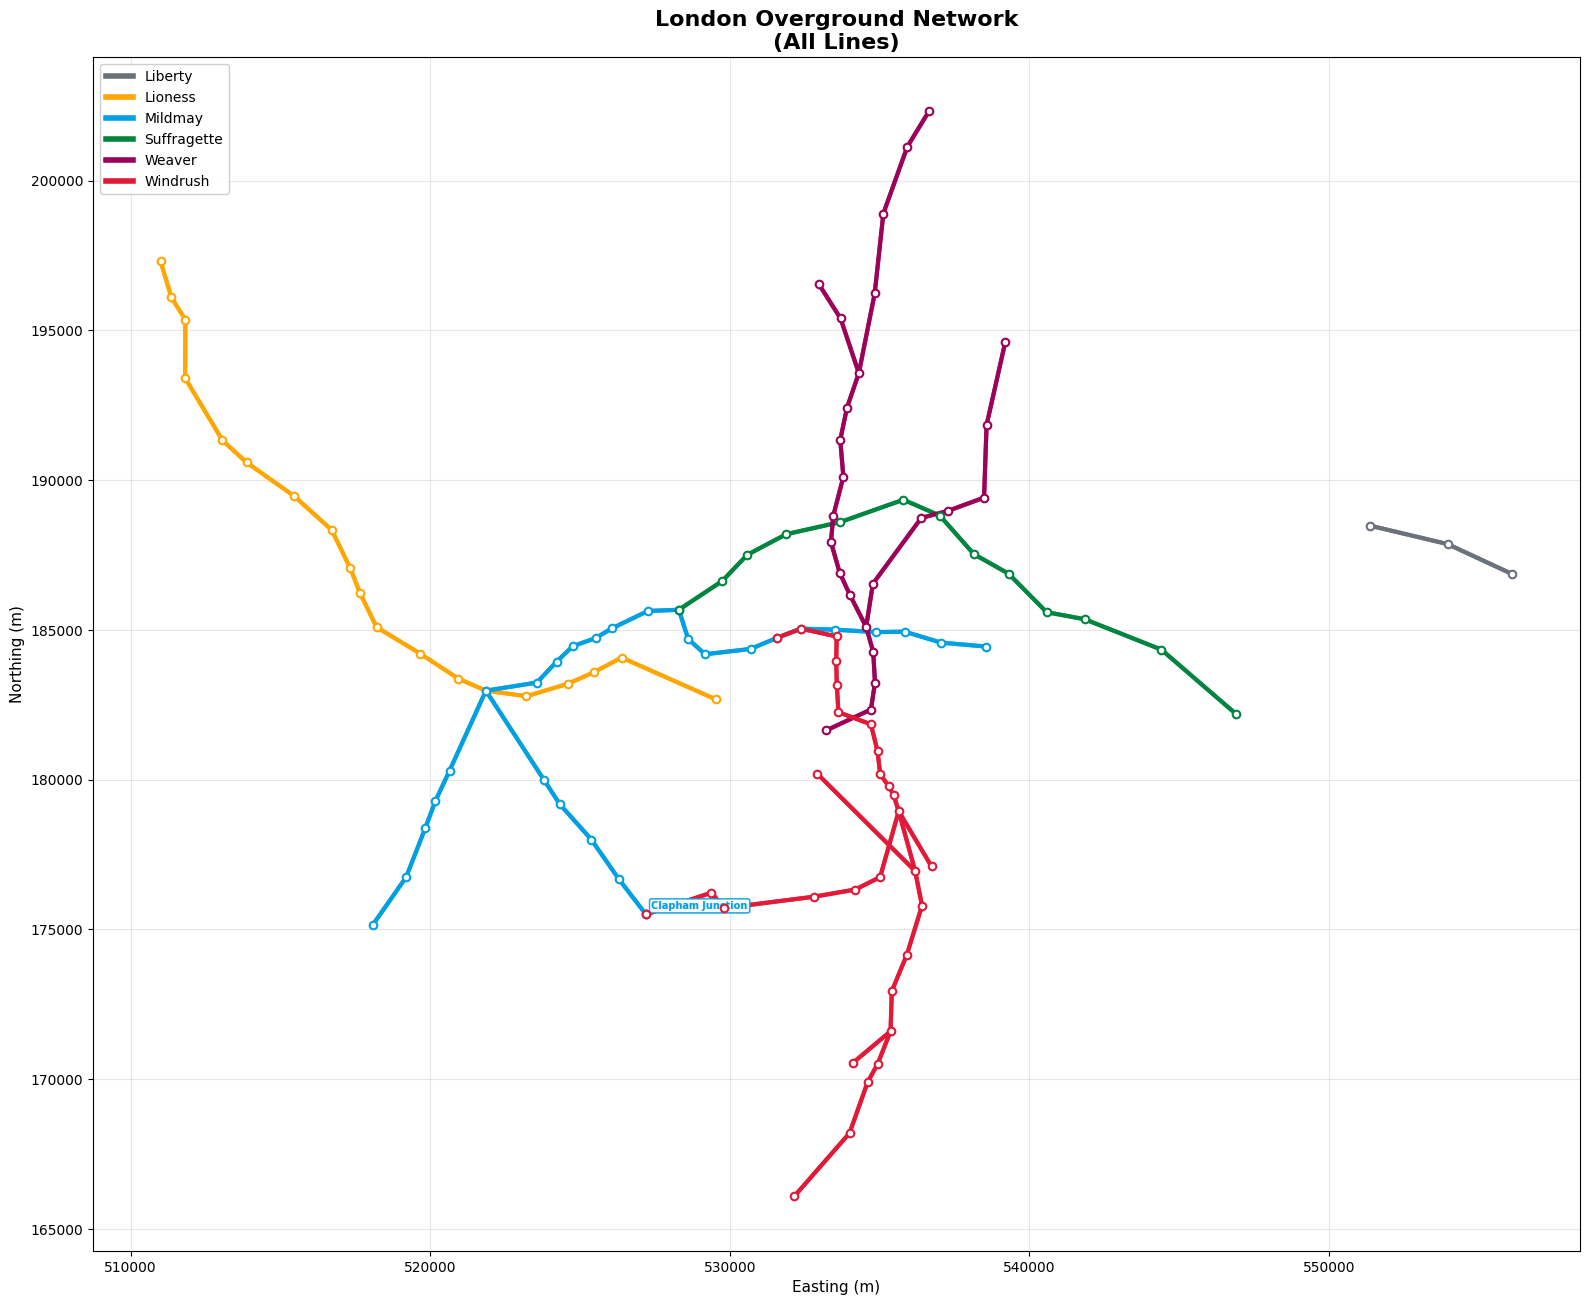

In [6]:
fig, ax = plt.subplots(figsize=(16, 18))

# Draw all Overground lines
for line_code, edges in overground_edges.items():
    color = OVERGROUND_COLORS[line_code]
    plot_line(ax, edges, stop_coords, color, linewidth=3, alpha=0.9)

# Get all Overground stations
network_stations = get_network_stations(overground_edges, stop_coords)

# Draw stations with their line colors
for line_code, edges in overground_edges.items():
    color = OVERGROUND_COLORS[line_code]
    line_stations = set(edges['From_StopPointRef'].tolist() + edges['To_StopPointRef'].tolist())
    for station in line_stations:
        if station in stop_coords:
            ax.scatter(stop_coords[station]['Easting'], stop_coords[station]['Northing'],
                      c='white', s=30, edgecolors=color, linewidth=1.5, zorder=10)

# Label terminus stations
labeled = set()
for line_code, edges in overground_edges.items():
    color = OVERGROUND_COLORS[line_code]
    terminus = get_terminus_stations(edges)
    for station in terminus:
        if station in stop_coords and station not in labeled:
            station_name = stop_coords[station].get('Descriptor_CommonName', '')
            if station_name:
                ax.annotate(station_name, 
                           (stop_coords[station]['Easting'], stop_coords[station]['Northing']),
                           xytext=(4, 4), textcoords='offset points',
                           fontsize=7, color=color, fontweight='bold',
                           bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor=color))
                labeled.add(station)

ax.set_xlabel('Easting (m)', fontsize=11)
ax.set_ylabel('Northing (m)', fontsize=11)
ax.set_title('London Overground Network\n(All Lines)', fontsize=16, fontweight='bold')
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)

# Legend
legend_elements = [Line2D([0], [0], color=OVERGROUND_COLORS[code], linewidth=4, 
                          label=OVERGROUND_NAMES[code])
                   for code in OVERGROUND_COLORS.keys() if code in overground_edges]
ax.legend(handles=legend_elements, loc='upper left', fontsize=10, framealpha=0.95)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'overground_complete.png', dpi=150, bbox_inches='tight')
plt.show()

## Overground Network with Coverage Area

In [7]:
def create_coverage_hull(stations, stop_coords, buffer_m=1500):
    """Create a convex hull around all stations with optional buffer."""
    points = np.array([[stop_coords[s]['Easting'], stop_coords[s]['Northing']] 
                       for s in stations])
    
    hull = ConvexHull(points)
    hull_points = points[hull.vertices]
    
    # Add buffer by expanding from centroid
    if buffer_m > 0:
        centroid = np.mean(hull_points, axis=0)
        directions = hull_points - centroid
        distances = np.linalg.norm(directions, axis=1, keepdims=True)
        unit_directions = directions / distances
        hull_points = hull_points + unit_directions * buffer_m
    
    return hull_points

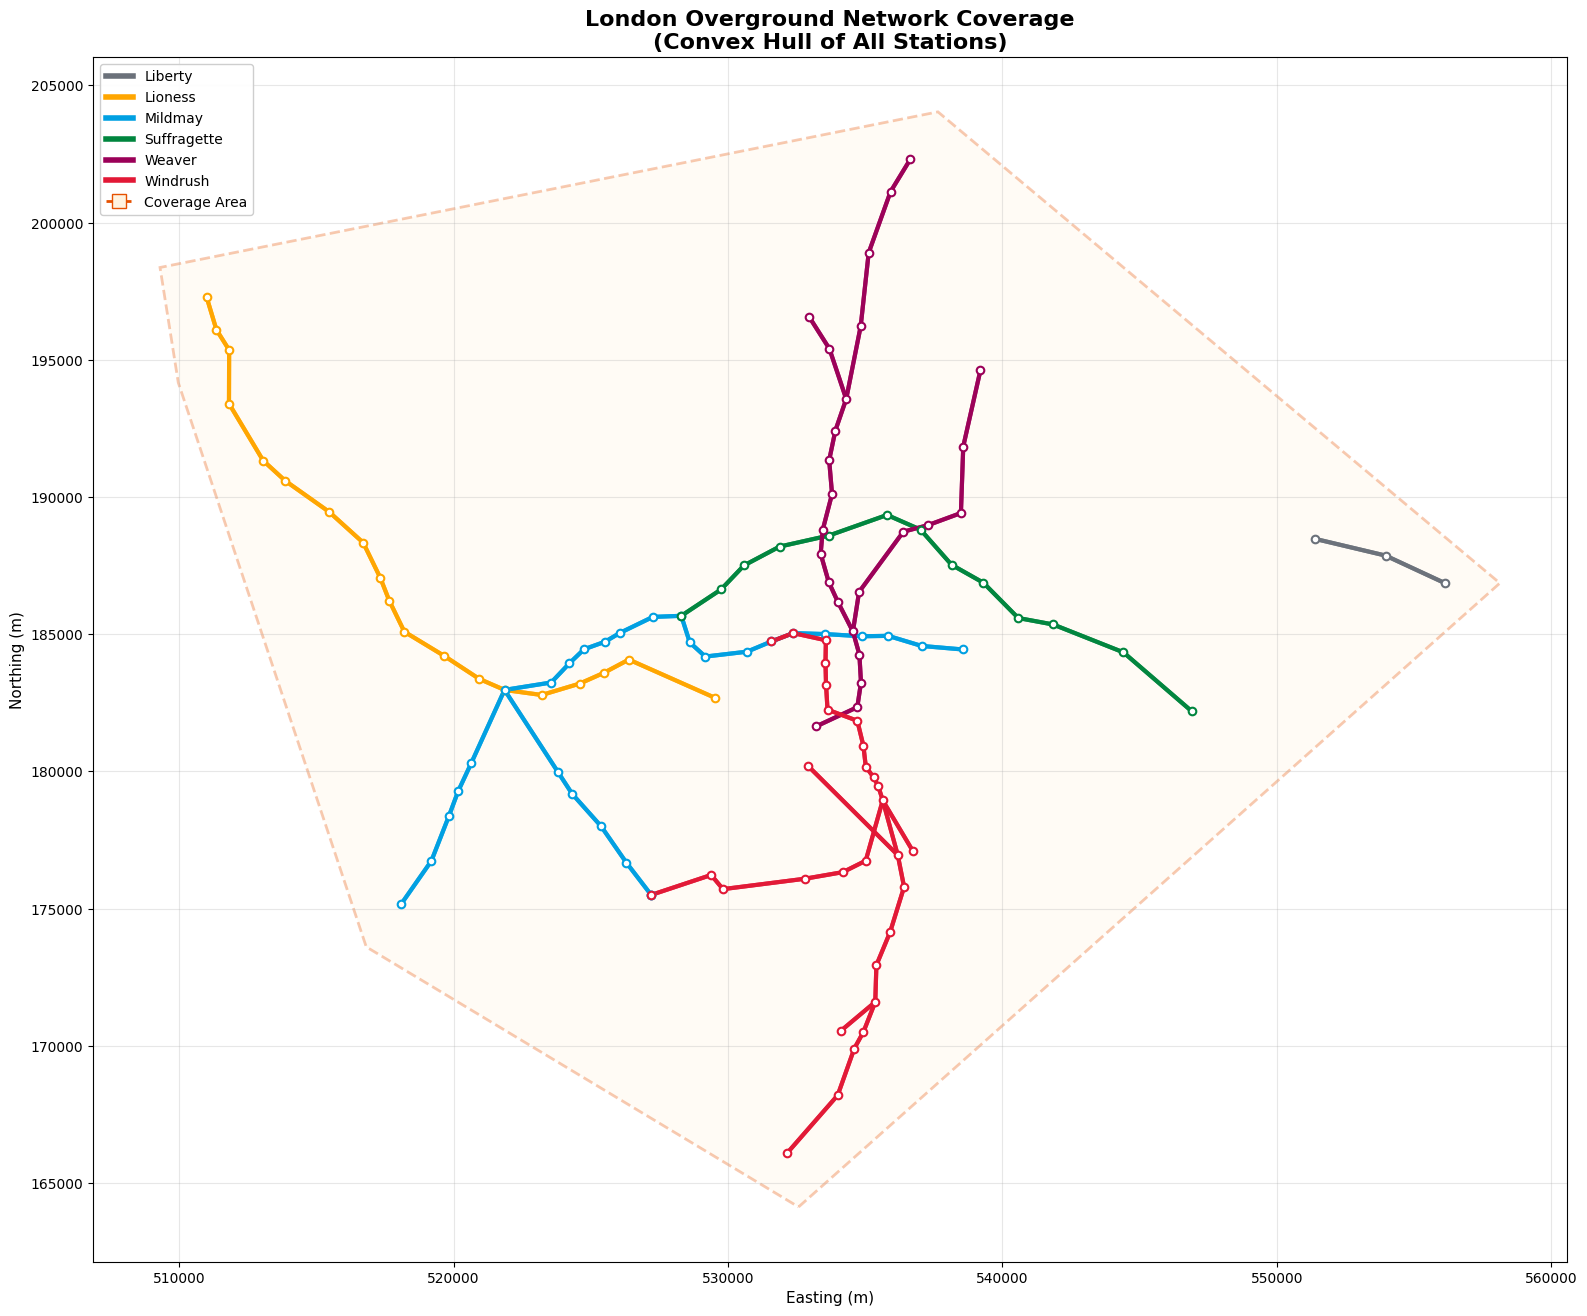

In [8]:
fig, ax = plt.subplots(figsize=(16, 18))

# Get network stations
network_stations = get_network_stations(overground_edges, stop_coords)

# Create and draw coverage area
hull_points = create_coverage_hull(network_stations, stop_coords, buffer_m=2000)
coverage_polygon = Polygon(hull_points, closed=True, 
                           facecolor='#FFF3E0', edgecolor='#E65100', 
                           alpha=0.3, linewidth=2, linestyle='--',
                           zorder=1)
ax.add_patch(coverage_polygon)

# Draw all Overground lines
for line_code, edges in overground_edges.items():
    color = OVERGROUND_COLORS[line_code]
    plot_line(ax, edges, stop_coords, color, linewidth=3, alpha=0.9)

# Draw stations
for line_code, edges in overground_edges.items():
    color = OVERGROUND_COLORS[line_code]
    line_stations = set(edges['From_StopPointRef'].tolist() + edges['To_StopPointRef'].tolist())
    for station in line_stations:
        if station in stop_coords:
            ax.scatter(stop_coords[station]['Easting'], stop_coords[station]['Northing'],
                      c='white', s=30, edgecolors=color, linewidth=1.5, zorder=10)

ax.set_xlabel('Easting (m)', fontsize=11)
ax.set_ylabel('Northing (m)', fontsize=11)
ax.set_title('London Overground Network Coverage\n(Convex Hull of All Stations)', fontsize=16, fontweight='bold')
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)

# Legend
legend_elements = [Line2D([0], [0], color=OVERGROUND_COLORS[code], linewidth=4, 
                          label=OVERGROUND_NAMES[code])
                   for code in OVERGROUND_COLORS.keys() if code in overground_edges]
legend_elements.append(Line2D([0], [0], color='#E65100', linewidth=2, linestyle='--',
                              marker='s', markersize=10, markerfacecolor='#FFF3E0',
                              markeredgecolor='#E65100', label='Coverage Area'))
ax.legend(handles=legend_elements, loc='upper left', fontsize=10, framealpha=0.95)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'overground_coverage.png', dpi=150, bbox_inches='tight')
plt.show()

## Side-by-Side Comparison of All Lines

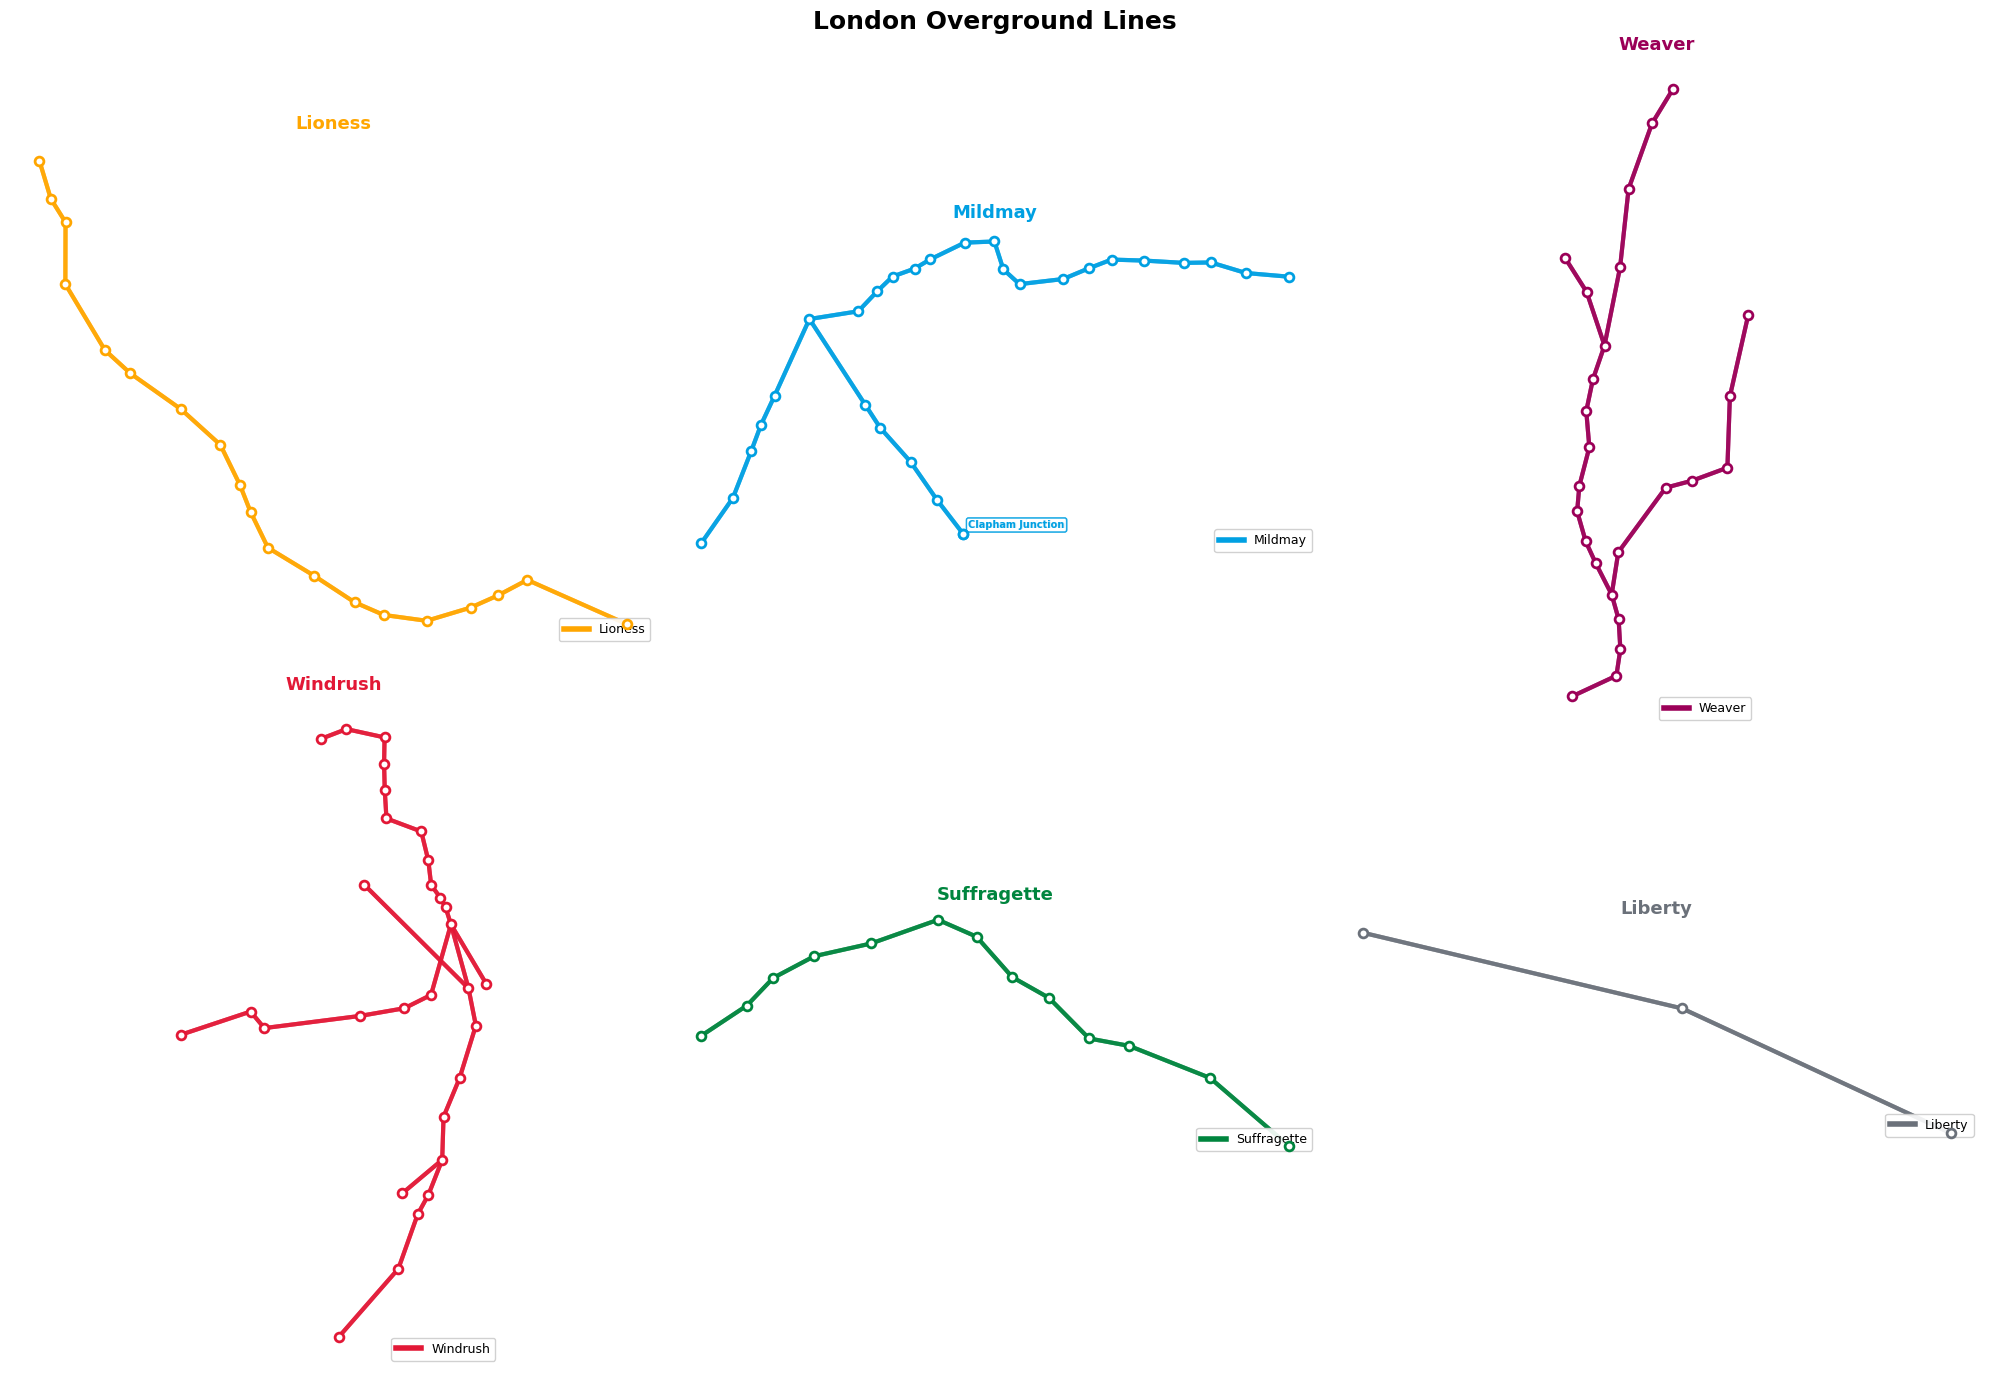

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(20, 14))
axes = axes.flatten()

line_order = ['LIO', 'MIL', 'WEA', 'WIN', 'SUF', 'LIB']

for idx, line_code in enumerate(line_order):
    ax = axes[idx]
    
    if line_code not in overground_edges:
        ax.text(0.5, 0.5, f'No data for {OVERGROUND_NAMES[line_code]}', 
                ha='center', va='center', transform=ax.transAxes, fontsize=12)
        ax.axis('off')
        continue
    
    edges = overground_edges[line_code]
    color = OVERGROUND_COLORS[line_code]
    name = OVERGROUND_NAMES[line_code]
    
    # Get stations
    line_stations = set(edges['From_StopPointRef'].tolist() + edges['To_StopPointRef'].tolist())
    
    # Draw edges
    plot_line(ax, edges, stop_coords, color, linewidth=3)
    
    # Draw stations
    for station in line_stations:
        if station in stop_coords:
            ax.scatter(stop_coords[station]['Easting'], stop_coords[station]['Northing'],
                      c='white', s=40, edgecolors=color, linewidth=2, zorder=10)
    
    # Label terminus
    terminus = get_terminus_stations(edges)
    for station in terminus:
        if station in stop_coords:
            station_name = stop_coords[station].get('Descriptor_CommonName', '')
            if station_name:
                ax.annotate(station_name, 
                           (stop_coords[station]['Easting'], stop_coords[station]['Northing']),
                           xytext=(4, 4), textcoords='offset points',
                           fontsize=7, color=color, fontweight='bold',
                           bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor=color))
    
    ax.set_title(name, fontsize=13, color=color, fontweight='bold')
    ax.set_aspect('equal')
    ax.axis('off')
    
    # Legend
    legend_element = [Line2D([0], [0], color=color, linewidth=4, label=name)]
    ax.legend(handles=legend_element, loc='lower right', fontsize=9, framealpha=0.9)

plt.suptitle('London Overground Lines', fontsize=18, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'overground_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## Network Statistics

In [10]:
print("=" * 70)
print("LONDON OVERGROUND NETWORK STATISTICS")
print("=" * 70)

total_stations = len(get_network_stations(overground_edges, stop_coords))
total_edges = sum(len(edges) for edges in overground_edges.values())

print(f"\nTotal Stations: {total_stations}")
print(f"Total Connections: {total_edges}")
print(f"Total Lines: {len(overground_edges)}")

# Calculate network extent
network_stations = get_network_stations(overground_edges, stop_coords)
all_x = [stop_coords[s]['Easting'] for s in network_stations]
all_y = [stop_coords[s]['Northing'] for s in network_stations]

width_km = (max(all_x) - min(all_x)) / 1000
height_km = (max(all_y) - min(all_y)) / 1000

print(f"\nNetwork Extent:")
print(f"  Width (E-W): {width_km:.1f} km")
print(f"  Height (N-S): {height_km:.1f} km")

# Coverage area
points = np.array([[stop_coords[s]['Easting'], stop_coords[s]['Northing']] 
                   for s in network_stations])
hull = ConvexHull(points)
coverage_km2 = hull.volume / 1e6
print(f"  Coverage Area: {coverage_km2:.1f} km²")

print("\n" + "-" * 70)
print("BY LINE:")
print("-" * 70)
print(f"{'Line':<15} {'Stations':>10} {'Connections':>12} {'Length (km)':>12}")
print("-" * 70)

for line_code in OVERGROUND_COLORS.keys():
    if line_code not in overground_edges:
        continue
    
    edges = overground_edges[line_code]
    line_stations = set(edges['From_StopPointRef'].tolist() + edges['To_StopPointRef'].tolist())
    valid_stations = [s for s in line_stations if s in stop_coords]
    
    # Calculate total length
    total_length = 0
    for _, edge in edges.iterrows():
        from_stop = edge['From_StopPointRef']
        to_stop = edge['To_StopPointRef']
        if from_stop in stop_coords and to_stop in stop_coords:
            dx = stop_coords[to_stop]['Easting'] - stop_coords[from_stop]['Easting']
            dy = stop_coords[to_stop]['Northing'] - stop_coords[from_stop]['Northing']
            total_length += np.sqrt(dx**2 + dy**2)
    
    print(f"{OVERGROUND_NAMES[line_code]:<15} {len(valid_stations):>10} {len(edges):>12} {total_length/1000:>12.1f}")

print("=" * 70)

LONDON OVERGROUND NETWORK STATISTICS

Total Stations: 114
Total Connections: 224
Total Lines: 6

Network Extent:
  Width (E-W): 45.1 km
  Height (N-S): 36.2 km
  Coverage Area: 969.2 km²

----------------------------------------------------------------------
BY LINE:
----------------------------------------------------------------------
Line              Stations  Connections  Length (km)
----------------------------------------------------------------------
Liberty                  3            4         10.1
Lioness                 19           36         54.6
Mildmay                 29           54         73.0
Suffragette             13           24         44.1
Weaver                  25           48         74.8
Windrush                30           58         83.9
